In [1]:
# General imports

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import subprocess
import os
import sys
import math
import warnings
import re

# Plotting libraries

import plotly.express as px
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# Data Processing - General SSP

In [34]:


geo_csv = gpd.read_file("georef-canada-province-millesime.csv")
geo_shape = gpd.read_file("georef-canada-province-millesime.shp")

# Process shape ile into csv
geo_shape = geo_shape[geo_shape["year"] == "2021"]
df = pd.DataFrame(geo_shape.drop(columns=["geometry","year"]))




In [86]:
df = pd.read_csv('MESSAGE_CANADA_provincial_baseline_v1.csv')

In [88]:
import pyam

<IPython.core.display.Javascript object>

In [89]:
df_pyam  = pyam.IamDataFrame(df)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/utils.py:347: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df.set_index(index + REQUIRED_COLS + extra_cols)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [93]:
vars_cost = df_pyam.filter(variable = 'Total Costs*').variable

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [95]:
pdf = df_pyam.aggregate("Total Costs", components = vars_cost)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7ff1606b0d30> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [97]:
pdf.to_csv('total_cost_bau.csv')

In [99]:
cost

,Model,Scenario,Region,Variable,Unit,2010,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
0,MESSAGEix-Canada,Reference,Alberta,Total Costs,NaN,0.0,0.0,42567.052299,40910.326206,37255.590811,34055.095539,33516.775690,32054.818086,34710.670523,36291.244249,37955.008975
1,MESSAGEix-Canada,Reference,BritishColumbia,Total Costs,NaN,0.0,0.0,36924.457225,37696.976342,40525.981261,41934.435639,43687.800769,43951.884788,46316.676969,47330.251896,48954.895745
2,MESSAGEix-Canada,Reference,Canada,Total Costs,NaN,0.0,0.0,368470.140978,216493.420380,205844.218387,201851.060048,204765.910336,207640.970350,222285.955107,237581.814028,258126.782960
3,MESSAGEix-Canada,Reference,Manitoba,Total Costs,NaN,0.0,0.0,7579.620637,7206.415707,7309.493805,7807.906933,8261.957840,8259.213195,8487.182210,9978.127503,10940.741364
4,MESSAGEix-Canada,Reference,NewBrunswick,Total Costs,NaN,0.0,0.0,6148.022210,6248.811190,5909.419106,5624.234859,5606.615018,4796.191549,6054.755555,6590.037657,7426.543148
5,MESSAGEix-Canada,Reference,NewfoundlandandLabrador,Total Costs,NaN,0.0,0.0,4520.463785,4195.758724,3867.303285,3729.516714,3755.160474,3912.376915,4548.751022,5124.226079,8356.095299
6,MESSAGEix-Canada,Reference,NorthwestTerritories,Total Costs,NaN,0.0,0.0,383.054755,218.527209,234.203371,271.502582,328.878440,483.367055,660.475967,937.842541,1088.484014
7,MESSAGEix-Canada,Reference,NovaScotia,Total Costs,NaN,0.0,0.0,6735.970447,7070.774646,6302.543559,5862.264932,5262.926805,5380.025347,5661.216653,6128.323908,7078.478290
8,MESSAGEix-Canada,Reference,Nunavut,Total Costs,NaN,0.0,0.0,172.239342,102.078655,115.473526,125.042692,250.490633,350.132288,519.188333,763.356094,910.983598
9,MESSAGEix-Canada,Reference,Ontario,Total Costs,NaN,0.0,0.0,60376.360980,53441.634613,48987.834290,47129.054659,47190.283158,49153.217604,51338.026259,53460.880645,55082.738914


,region,2020,2025,2030,2035,2040,2045,2050,2055,2060,prov_abr
0,Newfoundland and Labrador,2.069740e+11,2.296047e+11,2.522354e+11,2.782523e+11,3.042691e+11,3.312681e+11,3.582671e+11,3.865340e+11,4.148008e+11,NL
1,Prince Edward Island,2.317790e+10,2.569567e+10,2.821343e+10,3.113723e+10,3.406103e+10,3.712003e+10,4.017903e+10,4.340805e+10,4.663707e+10,PE
2,Nova Scotia,8.721279e+10,9.670389e+10,1.061950e+11,1.168192e+11,1.274435e+11,1.384000e+11,1.493565e+11,1.606338e+11,1.719110e+11,NS
3,New Brunswick,7.595142e+10,8.421865e+10,9.248589e+10,1.019162e+11,1.113464e+11,1.212434e+11,1.311403e+11,1.415267e+11,1.519131e+11,NB
4,Quebec,2.608469e+11,2.892580e+11,3.176691e+11,3.507933e+11,3.839175e+11,4.188318e+11,4.537461e+11,4.902507e+11,5.267553e+11,QC
5,Ontario,1.355188e+11,1.501663e+11,1.648139e+11,1.813617e+11,1.979095e+11,2.150902e+11,2.322708e+11,2.501731e+11,2.680754e+11,ON
6,Manitoba,2.057228e+11,2.282130e+11,2.507032e+11,2.765732e+11,3.024432e+11,3.293330e+11,3.562227e+11,3.843291e+11,4.124355e+11,MB
7,Saskatchewan,3.675073e+10,4.081044e+10,4.487014e+10,4.952005e+10,5.416996e+10,5.909219e+10,6.401442e+10,6.902641e+10,7.403839e+10,SK
8,Alberta,3.280781e+11,3.639178e+11,3.997575e+11,4.412224e+11,4.826872e+11,5.259714e+11,5.692557e+11,6.145317e+11,6.598078e+11,AB
9,British Columbia,1.241384e+11,1.375727e+11,1.510070e+11,1.661909e+11,1.813747e+11,1.971032e+11,2.128318e+11,2.292117e+11,2.455917e+11,BC


In [35]:
geo_shape['region'] = geo_shape['prov_name_e'].str.replace(r"\['(.*?)'\]", r"\1", regex=True)

<Axes: >

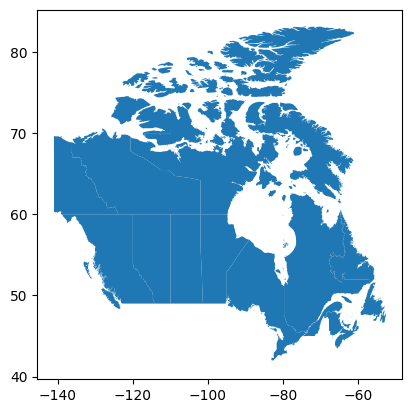

In [29]:
geo_shape.plot()

In [15]:

# Load the updated GDP projections CSV file
csv_file_path = 'SSP_GDP_Projections.csv'
gdp_df = pd.read_csv(csv_file_path)

In [30]:
merged_df = pd.merge(gdp_df, geo_shape, on='Region')

In [31]:
merged_df.columns

Index(['Region', '2020', '2025', '2030', '2035', '2040', '2045', '2050',
       '2055', '2060', 'year', 'prov_code', 'prov_name_e', 'prov_area_c',
       'prov_type', 'prov_name_f', 'geometry'],
      dtype='object')

In [37]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Assuming geo_shape is already a GeoDataFrame
# geo_shape = gpd.read_file('path_to_your_shapefile.shp')  # Uncomment if you need to load it

# Load the updated GDP projections CSV file
csv_file_path = 'SSP_GDP_Projections.csv'
gdp_df = pd.read_csv(csv_file_path)
gdp_df = gdp_df.rename(columns={'Region': 'region'})

# Display first few rows of the dataframes to understand their structure
print(geo_shape.head())
print(gdp_df.head())

# Ensure 'region' is the common column for merging, adjust the column names based on your actual data
# Assuming geo_shape has a column named 'province_name' and gdp_df has a column named 'region'
# Adjust these column names according to the actual column names in your data


# Verify that df_merged is a GeoDataFrame
print(type(df_merged))
print(df_merged.head())


    year prov_code                    prov_name_e prov_area_c  \
0   2021    ['24']                     ['Quebec']         CAN   
4   2021    ['48']                    ['Alberta']         CAN   
7   2021    ['60']                      ['Yukon']         CAN   
10  2021    ['10']  ['Newfoundland and Labrador']         CAN   
11  2021    ['13']              ['New Brunswick']         CAN   

                 prov_type              prov_name_f  \
0                 province                   Québec   
4                 province                  Alberta   
7   territory / territoire                    Yukon   
10                province  Terre-Neuve-et-Labrador   
11                province        Nouveau-Brunswick   

                                             geometry  \
0   MULTIPOLYGON (((-73.86407 45.51852, -73.91222 ...   
4   POLYGON ((-110.00502 48.99970, -110.44096 48.9...   
7   MULTIPOLYGON (((-139.13388 69.63737, -138.9589...   
10  MULTIPOLYGON (((-53.63678 48.87151, -53.72101 

In [146]:
gdp_df['msgreg'] = gdp_df['region'].str.replace(' ', '')
cost = pd.read_csv('total_cost_bau.csv')
cost['msgreg'] = cost['Region']
cost = cost[~(cost['msgreg'] == 'Canada')]
cost_gdp = cost.merge(gdp_df, on = 'msgreg', how = 'left')
cost_gdp['2030_y_million'] = cost_gdp['2030_y']/1e6
cost_gdp['ratio'] = (cost_gdp['2030_x']/cost_gdp['2030_y_million'])*100
# Merge the shapefile data with the GDP projections data
df_merged = geo_shape.merge(cost_gdp, on='region', how='left')

In [147]:
gdp_df['msgreg']

0     NewfoundlandandLabrador
1          PrinceEdwardIsland
2                  NovaScotia
3                NewBrunswick
4                      Quebec
5                     Ontario
6                    Manitoba
7                Saskatchewan
8                     Alberta
9             BritishColumbia
10                      Yukon
11       NorthwestTerritories
12                    Nunavut
Name: msgreg, dtype: object

In [148]:
cost_gdp['ratio']

0      9.319547
1     26.837148
2      2.915597
3      6.389536
4      1.533212
5      0.469000
6      5.934879
7      0.361530
8     29.723127
9      3.526870
10    13.186908
11    27.490969
12     0.336419
Name: ratio, dtype: float64

In [140]:
cost_gdp['2030_y']

0     3.997575e+11
1              NaN
2     2.507032e+11
3              NaN
4              NaN
5              NaN
6              NaN
7     3.194020e+10
8     1.648139e+11
9              NaN
10    3.176691e+11
11    4.487014e+10
12    3.428812e+10
Name: 2030_y, dtype: float64

In [141]:
cost_gdp['2030_y_million']

0     399757.512533
1               NaN
2     250703.179307
3               NaN
4               NaN
5               NaN
6               NaN
7      31940.203520
8     164813.864960
9               NaN
10    317669.124779
11     44870.144000
12     34288.115371
Name: 2030_y_million, dtype: float64

In [142]:
cost['2030']

0     37255.590811
1     40525.981261
3      7309.493805
4      5909.419106
5      3867.303285
6       234.203371
7      6302.543559
8       115.473526
9     48987.834290
10      995.051070
11    41890.735147
12    12335.237580
13      115.351576
Name: 2030, dtype: float64

In [111]:
cost_gdp['ratio']

0     9.319547
1     2.915597
2     0.361530
3    29.723127
4    13.186908
5    27.490969
6     0.336419
Name: ratio, dtype: float64

In [ ]:
gdp

In [149]:
# Create a dictionary for region abbreviations
region_abbreviations = {
    'Quebec': 'QC',
    'Alberta': 'AB',
    'Yukon': 'YT',
    'Newfoundland and Labrador': 'NL',
    'New Brunswick': 'NB',
    'Manitoba': 'MB',
    'Northwest Territories': 'NT',
    'Prince Edward Island': 'PE',
    'Saskatchewan': 'SK',
    'British Columbia': 'BC',
    'Nova Scotia': 'NS',
    'Nunavut': 'NU',
    'Ontario': 'ON'
}

# Add a new column for the region abbreviations
df_merged['prov_abr'] = df_merged['region'].map(region_abbreviations)

In [115]:
df_merged['ratio']

0     13.186908
1      9.319547
2      0.336419
3           NaN
4           NaN
5      2.915597
6           NaN
7           NaN
8     27.490969
9           NaN
10          NaN
11     0.361530
12    29.723127
Name: ratio, dtype: float64

In [75]:
df_merged['2050_b'] = (df_merged['2050']/1e9)

In [160]:
df_merged['2030_y_billion'] = df_merged['2030_y_million']/1e3

In [79]:
df_merged['2030'].sum()

1924115662935.0

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_5277/441811851.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df_merged['centroid'] = df_merged.geometry.centroid


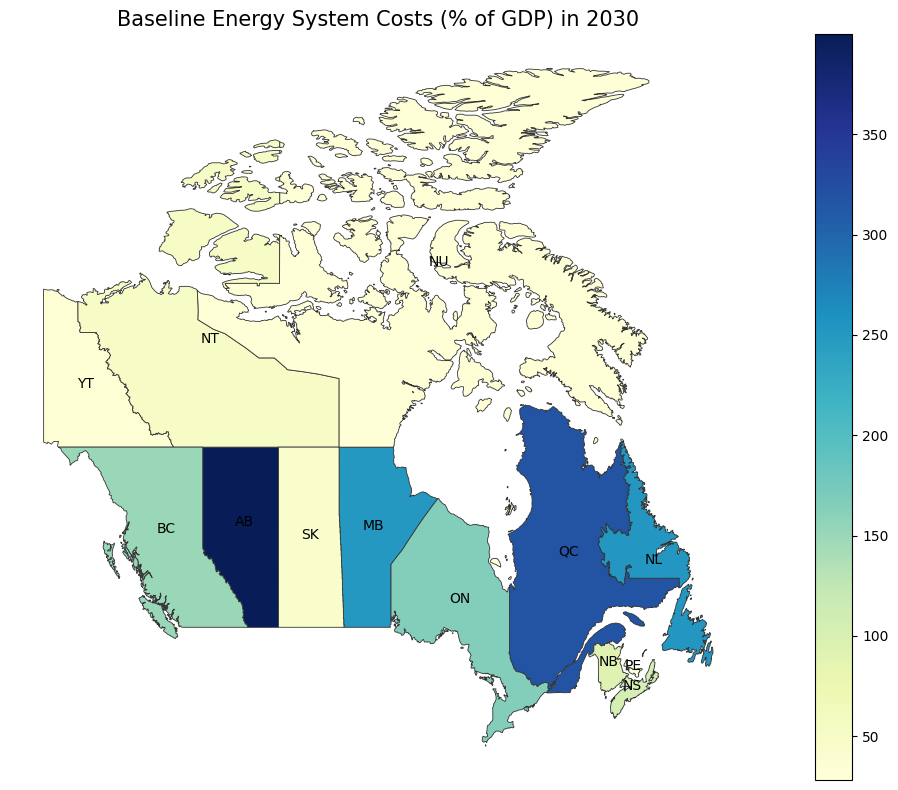

In [161]:
# Calculate centroids of each polygon for text placement
df_merged['centroid'] = df_merged.geometry.centroid
# Plot the '2050' column on a map using geopandas plotting function
fig, ax = plt.subplots(1, figsize=(14, 8))
df_merged.plot(column='2030_y_billion',  # Replace '2050' with the actual column name for the GDP values
               cmap='YlGnBu', linewidth=0.6, edgecolor='0.2',
               legend=True,  ax=ax)

# Add text annotations for the region abbreviations at centroid locations
for idx, row in df_merged.iterrows():
    plt.annotate(text=row['prov_abr'], xy=(row['centroid'].x, row['centroid'].y),
                 horizontalalignment='center', fontsize=10, color='black')

ax.axis('off')

ax.set_title("Baseline Energy System Costs (% of GDP) in 2030", fontdict={'fontsize': 15})

plt.tight_layout()
plt.savefig('cost_gdp_2030.png', dpi=400)
plt.show()


In [ ]:
# Calculate centroids of each polygon for text placement
df_merged['centroid'] = df_merged.geometry.centroid
# Plot the '2050' column on a map using geopandas plotting function
fig, ax = plt.subplots(1, figsize=(14, 8))
df_merged.plot(column='2050_b',  # Replace '2050' with the actual column name for the GDP values
               cmap='YlGnBu', linewidth=0.6, edgecolor='0.2',
               legend=True,  ax=ax)

# Add text annotations for the region abbreviations at centroid locations
for idx, row in df_merged.iterrows():
    plt.annotate(text=row['prov_abr'], xy=(row['centroid'].x, row['centroid'].y),
                 horizontalalignment='center', fontsize=10, color='black')

ax.axis('off')

ax.set_title("GDP in 2050 (billion USD)", fontdict={'fontsize': 25})

plt.tight_layout()
# plt.savefig('images/gdp_projections_2050.png', dpi=400)
plt.show()


In [26]:
merged_df

,Region,2020,2025,2030,2035,2040,2045,2050,2055,2060,year,prov_code,prov_name_e,prov_area_c,prov_type,prov_name_f,geometry
0,Newfoundland and Labrador,2.069740e+11,2.296047e+11,2.522354e+11,2.782523e+11,3.042691e+11,3.312681e+11,3.582671e+11,3.865340e+11,4.148008e+11,2021,['10'],Newfoundland and Labrador,CAN,province,Terre-Neuve-et-Labrador,"MULTIPOLYGON (((-53.63678 48.87151, -53.72101 ..."
1,Prince Edward Island,2.317790e+10,2.569567e+10,2.821343e+10,3.113723e+10,3.406103e+10,3.712003e+10,4.017903e+10,4.340805e+10,4.663707e+10,2021,['11'],Prince Edward Island,CAN,province,Île-du-Prince-Édouard,"POLYGON ((-61.98606 46.46286, -62.00568 46.429..."
2,Nova Scotia,8.721279e+10,9.670389e+10,1.061950e+11,1.168192e+11,1.274435e+11,1.384000e+11,1.493565e+11,1.606338e+11,1.719110e+11,2021,['12'],Nova Scotia,CAN,province,Nouvelle-Écosse,"MULTIPOLYGON (((-65.60612 43.51377, -65.55855 ..."
3,New Brunswick,7.595142e+10,8.421865e+10,9.248589e+10,1.019162e+11,1.113464e+11,1.212434e+11,1.311403e+11,1.415267e+11,1.519131e+11,2021,['13'],New Brunswick,CAN,province,Nouveau-Brunswick,"MULTIPOLYGON (((-66.93908 45.02470, -66.95651 ..."
4,Quebec,2.608469e+11,2.892580e+11,3.176691e+11,3.507933e+11,3.839175e+11,4.188318e+11,4.537461e+11,4.902507e+11,5.267553e+11,2021,['24'],Quebec,CAN,province,Québec,"MULTIPOLYGON (((-73.86407 45.51852, -73.91222 ..."
5,Ontario,1.355188e+11,1.501663e+11,1.648139e+11,1.813617e+11,1.979095e+11,2.150902e+11,2.322708e+11,2.501731e+11,2.680754e+11,2021,['35'],Ontario,CAN,province,Ontario,"MULTIPOLYGON (((-79.91454 44.99301, -80.00895 ..."
6,Manitoba,2.057228e+11,2.282130e+11,2.507032e+11,2.765732e+11,3.024432e+11,3.293330e+11,3.562227e+11,3.843291e+11,4.124355e+11,2021,['46'],Manitoba,CAN,province,Manitoba,"POLYGON ((-94.82808 60.00000, -94.85275 59.971..."
7,Saskatchewan,3.675073e+10,4.081044e+10,4.487014e+10,4.952005e+10,5.416996e+10,5.909219e+10,6.401442e+10,6.902641e+10,7.403839e+10,2021,['47'],Saskatchewan,CAN,province,Saskatchewan,"POLYGON ((-102.00000 60.00000, -102.00739 59.7..."
8,Alberta,3.280781e+11,3.639178e+11,3.997575e+11,4.412224e+11,4.826872e+11,5.259714e+11,5.692557e+11,6.145317e+11,6.598078e+11,2021,['48'],Alberta,CAN,province,Alberta,"POLYGON ((-110.00502 48.99970, -110.44096 48.9..."
9,British Columbia,1.241384e+11,1.375727e+11,1.510070e+11,1.661909e+11,1.813747e+11,1.971032e+11,2.128318e+11,2.292117e+11,2.455917e+11,2021,['59'],British Columbia,CAN,province,Colombie-Britannique,"MULTIPOLYGON (((-124.68935 49.54964, -124.6251..."


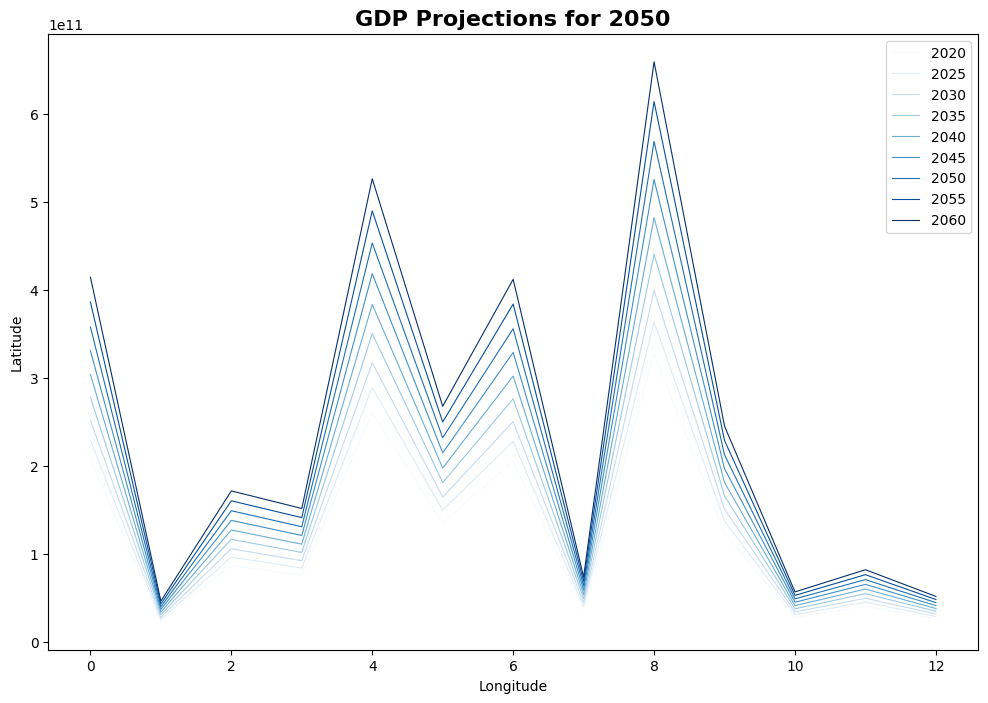

In [28]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Assuming merged_df is already created and contains the '2050' column

# Plot the '2050' column on a map using matplotlib
fig, ax = plt.subplots(figsize=(12, 8))
merged_df.plot(column='2050', cmap='Blues', linewidth=0.8, ax=ax, legend=True)

# Set the title and axis labels
ax.set_title('GDP Projections for 2050', fontdict={'fontsize': 16, 'fontweight': 'bold'})
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Show the plot
plt.show()

In [10]:
import shapefile
import geopandas as gpd
import pandas as pd
from shapely.geometry import Polygon, MultiPolygon, shape
import matplotlib.pyplot as plt

# Load the shapefile using the shapefile library
shapefile_path = 'georef-canada-province-millesime.shp'
sf = shapefile.Reader(shapefile_path)

# Extract geometries and properties
geoms = []
properties = []
for sr in sf.shapeRecords():
    geom = sr.shape.__geo_interface__
    if geom['type'] == 'MultiPolygon':
        for poly in shape(geom):
            geoms.append(poly)
            properties.append(sr.record.as_dict())
    else:
        geoms.append(shape(geom))
        properties.append(sr.record.as_dict())

# Create a GeoDataFrame from the processed geometries
gdf = gpd.GeoDataFrame(properties, geometry=geoms)

# Load the updated GDP projections CSV file
csv_file_path = 'SSP_GDP_Projections.csv'
gdp_df = pd.read_csv(csv_file_path)

# Display first few rows of the dataframes to understand their structure
gdf_head = gdf.head()
gdp_df_head = gdp_df.head()

gdf_head, gdp_df_head


TypeError: 'MultiPolygon' object is not iterable

In [6]:
pip install shapefile

ERROR: Could not find a version that satisfies the requirement shapefile (from versions: none)
ERROR: No matching distribution found for shapefile
Note: you may need to restart the kernel to use updated packages.


# Plots

First prepare dataframe for plots, then plot it using plotly

In [8]:

original_df = pd.read_csv(os.getcwd() + "\\Canada_Population.csv", sep=",", header=0, index_col=0)
input_gdp = pd.read_csv("Canada_GDP.csv", sep=",", header=0, index_col=0)

prov_list = [i for i in population_df.index]
prov_list = prov_list[:-1]


##########################################################

compare_dict = {"Year": [i for i in range(2020,2061,5)]} # Create year range


for prov in prov_list:
    statscan_list = list(population_df.loc[f"{prov}",population_df.columns == "2021"].values)
    for y in compare_dict["Year"]:
        if str(y) in population_df.columns:
            statscan_list.append(population_df.loc[f"{prov}", population_df.columns == str(y)].values[0])
        
    compare_dict[f"StatsCan_Projection_{prov}"] =  statscan_list

    compare_dict[f"SSP_Data_{prov}"] = list(original_df.loc[original_df["prov_name_e"] == f"['{prov}']",original_df.columns >= "sum.X2020"].values)
    compare_dict[f"{prov}_GDP"] = list(input_gdp.loc[input_gdp["prov_name_e"] == f"['{prov}']", input_gdp.columns >= "sum.X2020"].values)

    # Average 3 coordinates from the grid for each province
    a = list(np.round(np.mean(compare_dict[f"SSP_Data_{prov}"], axis=0)))
    a = a[0:5]
    #print(a)
    a = interpolate_list(a)
    #print(a)

    a2 = []
    for element in a:
        a2.append(element/10)
    compare_dict[f"SSP_Data_{prov}"] = a2

    gdp = list(np.round(np.mean(compare_dict[f"{prov}_GDP"], axis=0)))
    gdp = gdp[0:5]
    #print(gdp)
    gdp = interpolate_list(gdp)
    #print(gdp)
    compare_dict[f"{prov}_GDP"] = gdp

    b = []
    for k in compare_dict[f"StatsCan_Projection_{prov}"]: 
        k *= 1000 # Population numbers in the original sheet were scaled down by 1e3
        b.append(k)
    compare_dict[f"StatsCan_Projection_{prov}"] = b

#print(compare_dict)

#print(compare_dict["Year"],"\n")

for k,v in compare_dict.items():
    print(f"{k} ' : ' {len(v)}")



Year ' : ' 9
StatsCan_Projection_Newfoundland and Labrador ' : ' 9
SSP_Data_Newfoundland and Labrador ' : ' 9
Newfoundland and Labrador_GDP ' : ' 9
StatsCan_Projection_Prince Edward Island ' : ' 9
SSP_Data_Prince Edward Island ' : ' 9
Prince Edward Island_GDP ' : ' 9
StatsCan_Projection_Nova Scotia ' : ' 9
SSP_Data_Nova Scotia ' : ' 9
Nova Scotia_GDP ' : ' 9
StatsCan_Projection_New Brunswick ' : ' 9
SSP_Data_New Brunswick ' : ' 9
New Brunswick_GDP ' : ' 9
StatsCan_Projection_Quebec ' : ' 9
SSP_Data_Quebec ' : ' 9
Quebec_GDP ' : ' 9
StatsCan_Projection_Ontario ' : ' 9
SSP_Data_Ontario ' : ' 9
Ontario_GDP ' : ' 9
StatsCan_Projection_Manitoba ' : ' 9
SSP_Data_Manitoba ' : ' 9
Manitoba_GDP ' : ' 9
StatsCan_Projection_Saskatchewan ' : ' 9
SSP_Data_Saskatchewan ' : ' 9
Saskatchewan_GDP ' : ' 9
StatsCan_Projection_Alberta ' : ' 9
SSP_Data_Alberta ' : ' 9
Alberta_GDP ' : ' 9
StatsCan_Projection_British Columbia ' : ' 9
SSP_Data_British Columbia ' : ' 9
British Columbia_GDP ' : ' 9
StatsCan_Pro

In [9]:
compare_df = pd.DataFrame.from_dict(compare_dict)
#print(compare_df.head())

## Plotting Population

In [10]:


compare_fig = make_subplots(rows=len(prov_list) + 1, cols=1,
    subplot_titles=prov_list)


for i, prov in enumerate(prov_list):
    compare_fig.add_trace(go.Scatter(x=compare_df["Year"], 
        y=compare_df[f"StatsCan_Projection_{prov}"], name=f"StatsCan Prediction for {prov}"), row=i+1, col=1)
    
    compare_fig.append_trace(go.Scatter(x=compare_df["Year"],
        y=compare_df[f"SSP_Data_{prov}"], name=f"SSP_Data for {prov}"),i+1,1)
    
compare_fig.add_trace(go.Scatter(x=compare_df["Year"], y=population_df.loc["Year Sum",:],
    name="Total Population Prediction"), row=int(len(prov_list) + 1), col=1)

#compare_fig.add_trace(go.Scatter(x=compare_df["Year"], y=original_df))

for i in range(len(prov_list)):
    compare_fig.update_xaxes(title_text="Year", row=i+1, col=1)

compare_fig.update_layout(height=300*len(prov_list), width=700,title_text="Predictions for Each Province")

compare_fig.show()

# GDP Analysis Plots

Here we will analyse the GDP data for Canadian provinces

In [11]:
gdp_fig = px.line(compare_df, x="Year", y=f"{prov_list[5]}_GDP", 
    title="SSP GDP Projections")

ssp_gdp_df = pd.DataFrame()
ssp_gdp_df["Year"] = compare_df["Year"]

for i, prov in enumerate(prov_list):
    gdp_fig.add_scatter(x=compare_df["Year"], y=compare_df[f"{prov}_GDP"], name=prov)
    ssp_gdp_df[f"{prov}_GDP"] = compare_df[f"{prov}_GDP"]


gdp_fig.update_layout(xaxis_title="Year", yaxis_title="GDP [CAD$]")
gdp_fig.show()

ssp_gdp_df.to_csv(f"SSP_GDP_Projections.csv")




# Machine Learning - Predicting the Population Growth past 2043

Here we will employ machine learning to predict the population growth for all provinces past 2043, since the individual province data from StatsCan stops there. We can use the Canadian population growth predictions from StatsCan to validate the results afterwards

In [12]:
# Build input dataset
warnings.filterwarnings("ignore")

input_dataset = {"Year": population_df.columns}

for prov in prov_list:
    input_dataset[f"Population_{prov}"] = population_df.loc[f"{prov}",:].replace('..','NaN',regex=True).astype(float)

input_dataset = pd.DataFrame.from_dict(input_dataset)
input_dataset.drop_duplicates(keep="last", inplace=True)
input_dataset.dropna(inplace=True)

#print(input_dataset["Year"][18])


In [13]:
# Building training and testing datasets
warnings.filterwarnings("ignore")

population_target = f"Population_{input('Type province name: ')}"
print("Training for ", population_target, "\n")

## Getting cutoff for training
cutoff_year, training_cutoff = int(input_dataset["Year"][0]) + round(0.8*len(range(2021,2044))) - 1, round(0.8*len(range(2021,2044)))

print("\nCutoff year: ", cutoff_year, "\nIndex equivalent: ", training_cutoff)

# Splitting datasets

training_set = input_dataset.iloc[:training_cutoff,:]
training_years = training_set["Year"]
del training_set["Year"]
training_set = training_set[f"{population_target}"]

#print(training_set)
######################################################################

testing_set = input_dataset.iloc[training_cutoff:-1,:]
testing_years = testing_set["Year"]
del testing_set["Year"]

testing_set = testing_set[f"{population_target}"]

#print(testing_years)


Training for  Population_Alberta 


Cutoff year:  2038 
Index equivalent:  18


## Linear Regression

Here we will use Pytorch to create the model using a linear regression approach

In [14]:
# Try training and testing with a single province first, then do the entire dataset

x_lr, y_lr = training_years, training_set

torch_x = torch.tensor(training_years.values.astype(np.int64()))
torch_y = torch.tensor(training_set)

# Torch model
lr_features = torch_x.shape

torch_lr_model = nn.Linear(lr_features[0], lr_features[0]) # (inputs, outputs)

lr_loss = nn.MSELoss() # Error metrics: using root-mean-square error loss
lr_loss_history = []

lr_optim = torch.optim.Adam(torch_lr_model.parameters(), lr=0.01) # Optimizer
lr_epochs = 1 * 10**4 # More epochs give a lower RMSE

for ep in range(lr_epochs):
    # Forward pass
    torch_y_tilda = torch_lr_model(torch_x.float()) # Prediction
    curr_loss = lr_loss(torch_y_tilda, torch_y.float()) # Compare prediction and training value
    lr_loss_history.append(curr_loss)
    # Backward pass
    curr_loss.backward()
    # Update input and weight vector
    lr_optim.step()
    lr_optim.zero_grad() # Skip unnecessary information

lr_predictions = torch_lr_model(torch_x.float()).detach().numpy()

torch_RMSE = mean_squared_error(y_lr, lr_predictions, squared=False)
print(f"\nRMSE for {population_target}: {torch_RMSE}")




RMSE for Population_Alberta: 0.0001400118045188959


In [15]:
# Visuals

torch_figure = go.Figure()
torch_figure.add_trace(go.Scatter(x=training_years, y=lr_predictions,
    mode="lines", name=f"Predictions for {population_target}"))
torch_figure.add_trace(go.Scatter(x=training_years, y=y_lr,
    mode="lines", name="StatsCan Population Numbers"))
torch_figure.update_layout(title="PyTorch Linear Regression - Canadian Population Numbers",
    xaxis_title="Years", yaxis_title="Population Numbers [people x1,000]")


In [16]:
# Testing ML model
test_vector_years = [float(testing_years[-1])]
for i in range(int(testing_years[-1]),2060):
    test_vector_years.append(test_vector_years[-1] + 1)

testing_tensor = torch.tensor(test_vector_years)
test_predictions = torch_lr_model(testing_tensor[:len(torch_x)].float()).detach().numpy()

In [17]:
# View testing results

LR_test_figure = go.Figure()
LR_test_figure.add_trace(go.Scatter(x=test_vector_years, y=test_predictions, mode='lines', name='Predicted Population'))
LR_test_figure.add_trace(go.Scatter(x=test_vector_years, y=testing_set, mode='lines', name='StatsCan Predictions'))
LR_test_figure.update_layout(title=f'PyTorch Linear Regression - Test for {population_target}', xaxis_title='Years', yaxis_title='Population Numbers [people x1,000]')


# ARIMA Machine Learning

Using the ARIMA model, here we forecast the population growth for all provinces. The results are saved to a csv file

In [18]:
# Define ARIMA functions

# Function to fit ARIMA and predict future values
def predict_population(data):
    predictions = {}
    for index, col in data.iterrows():
        geography = index 
        time_series = pd.to_numeric(col[:], errors='coerce')
        time_series = time_series.dropna()
        model = ARIMA(time_series, order=(2, 1, 2))
        fitted_model = model.fit()
        forecast = fitted_model.forecast(steps=17)
        predictions[geography] = np.concatenate((time_series.values, forecast))
    return predictions

def plot_results(predictions, sc):
    Predict_figure = go.Figure()
    for geography, data in predictions.items():
        #if geography != 'Year Sum':
        Predict_figure.add_trace(go.Scatter(x=np.arange(2021, 2061), y=data, mode='lines',name=f"Population prediction for {geography}"))
    
    Predict_figure.update_layout(title=f'Population Forecast for {sc} Scenario',
        xaxis_title='Year', yaxis_title='Population (thousands)',
        width=800, height=500)
    Predict_figure.show()
    

def save_predicitions_to_csv(predictions,scenario):
    # Create a DataFrame from the predictions dictionary
    df = pd.DataFrame(predictions)
    # Set the year range as the index
    df.index = np.arange(2021, 2061)
    # Save to CSV
    df.to_csv(os.getcwd() + f'\\population_predictions_{scenario}.csv')
    print(f"Saved predictions to 'population_predictions_{scenario}.csv'")

def ARIMA_predict(data, sc):
    #data = load_data()
    predictions = predict_population(data)
    plot_results(predictions, sc)
    save_predicitions_to_csv(predictions, scenario=sc)  # Save the predictions to a CSV file

In [19]:
# Perform ARIMA predictions
ARIMA_df = population_df.iloc[:-1,:-1]
ARIMA_predict(ARIMA_df, scenario)

Saved predictions to 'population_predictions_MG1.csv'
